# Notebook 05 — Clustering Evaluation and Validation

**Goal:** Evaluate whether the customer clusters produced in Notebook 04 are reasonably separated, sufficiently sized, stable enough to interpret, and useful for customer profiling.

This notebook does not retrain the segmentation model by default. It loads the saved assignments, model, scaler, and feature matrix from Notebook 04 / Notebook 03.

We will examine:
1. Cluster size balance
2. Silhouette score
3. Davies–Bouldin index
4. Calinski–Harabasz index
5. PCA visualisation
6. Feature-level differences between clusters
7. Optional billing-status cross-tab (kept separate from behavioural clustering)

**Interpretation reminder:** no single metric proves that clusters are good. Use metrics, visualisation, cluster sizes, and business interpretability together.

## 1. Mount Google Drive and locate previous notebook outputs

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

MYDRIVE = Path('/content/drive/MyDrive')

assignment_matches = list(MYDRIVE.rglob('customer_cluster_assignments.csv'))
if not assignment_matches:
    raise FileNotFoundError(
        "customer_cluster_assignments.csv not found. Run Notebook 04 first."
    )

ASSIGNMENT_FILE = assignment_matches[0]
SEGMENT_DIR = ASSIGNMENT_FILE.parent
print("Segmentation output folder:", SEGMENT_DIR)


Mounted at /content/drive
Segmentation output folder: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k/processed/segmentation_outputs


## 2. Load assignments, model artifacts, and feature matrix

In [2]:
assignments = pd.read_csv(ASSIGNMENT_FILE)
model = joblib.load(SEGMENT_DIR / 'kmeans_model.joblib')
scaler = joblib.load(SEGMENT_DIR / 'standard_scaler.joblib')

metadata_path = SEGMENT_DIR / 'model_metadata.json'
with open(metadata_path, 'r') as f:
    metadata = json.load(f)

feature_columns = metadata['feature_columns']

feature_matches = list(MYDRIVE.rglob('customer_features_unscaled.csv'))
if not feature_matches:
    raise FileNotFoundError("customer_features_unscaled.csv not found. Run Notebook 03.")

feature_file = feature_matches[0]
X_raw = pd.read_csv(feature_file)
X = X_raw.drop(columns=[c for c in X_raw.columns if c.lower() in {'customer_id', 'id'}],
               errors='ignore').copy()

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

# Reproduce the feature selection used in Notebook 04.
X = X.reindex(columns=feature_columns)
if X.isna().any().any():
    X = X.fillna(X.median(numeric_only=True))

X_scaled = scaler.transform(X)

print("Assignments:", assignments.shape)
print("Feature matrix:", X.shape)
print("Model K:", model.n_clusters)
display(assignments.head())


Assignments: (20000, 2)
Feature matrix: (20000, 18)
Model K: 4


,customer_id,cluster
0,CUST000001,0
1,CUST000002,0
2,CUST000003,0
3,CUST000004,0
4,CUST000005,2


## 3. Cluster size and balance

,customer_count,percentage
cluster,,
0,10278,51.39
1,161,0.80
2,6146,30.73
3,3415,17.08


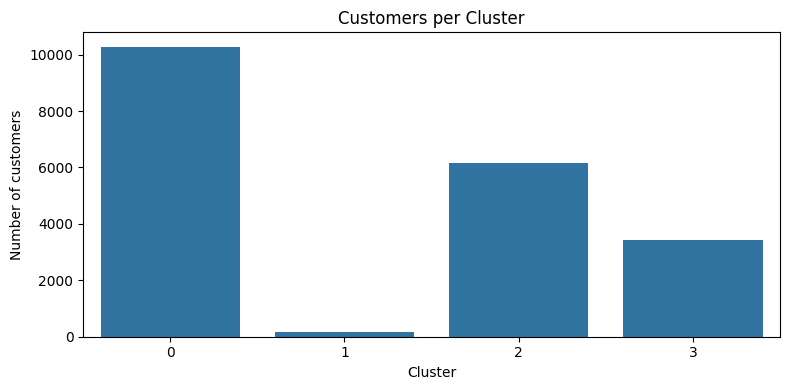

In [3]:
cluster_counts = assignments['cluster'].value_counts().sort_index()
cluster_percent = (cluster_counts / len(assignments) * 100).round(2)

size_summary = pd.DataFrame({
    'customer_count': cluster_counts,
    'percentage': cluster_percent
})
display(size_summary)

plt.figure(figsize=(8, 4))
sns.barplot(x=size_summary.index.astype(str), y=size_summary['customer_count'])
plt.title('Customers per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.show()


## 4. Internal clustering evaluation metrics

In [4]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

labels = assignments['cluster'].to_numpy()

# Silhouette can be expensive on large datasets; use a reproducible sample.
sample_size = min(5000, len(X_scaled))
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_scaled), size=sample_size, replace=False)

sil_score = silhouette_score(X_scaled[sample_idx], labels[sample_idx])
db_score = davies_bouldin_score(X_scaled, labels)
ch_score = calinski_harabasz_score(X_scaled, labels)

evaluation_metrics = pd.DataFrame({
    'metric': ['Silhouette Score', 'Davies-Bouldin Index', 'Calinski-Harabasz Index'],
    'value': [sil_score, db_score, ch_score],
    'preferred_direction': ['Higher (closer to 1)', 'Lower', 'Higher']
})
display(evaluation_metrics)


,metric,value,preferred_direction
0,Silhouette Score,0.286370,Higher (closer to 1)
1,Davies-Bouldin Index,1.132034,Lower
2,Calinski-Harabasz Index,7090.728285,Higher


### How to interpret these metrics

- **Silhouette Score:** measures how close each customer is to its own cluster compared with other clusters. Higher is generally better; values near zero indicate overlap, and negative values suggest possible misassignment.
- **Davies–Bouldin Index:** compares within-cluster spread with between-cluster separation. Lower is generally better.
- **Calinski–Harabasz Index:** compares between-cluster dispersion with within-cluster dispersion. Higher is generally better.

Do not apply universal pass/fail thresholds. Compare candidate K values on the same dataset and feature set, and consider business usefulness.

## 5. PCA visualisation

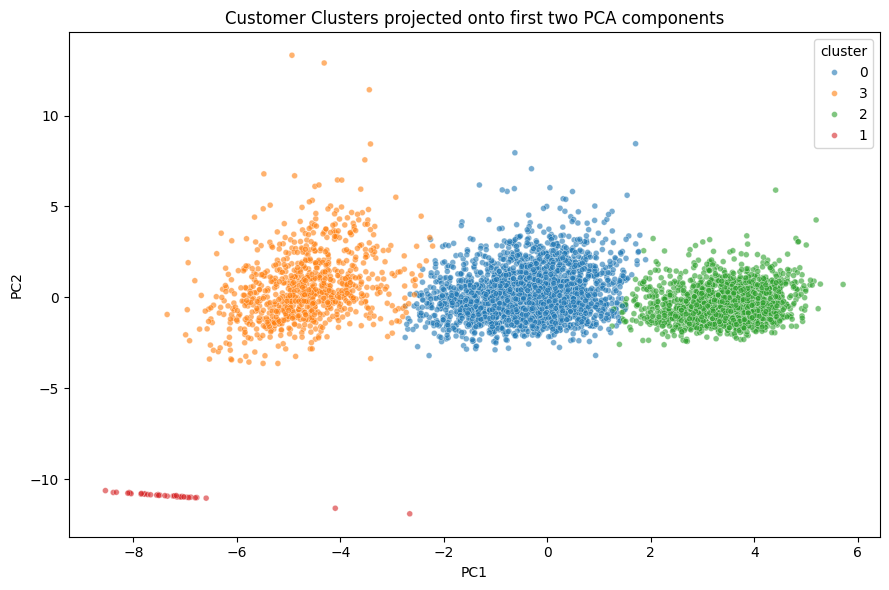

Explained variance by PC1 and PC2: 0.6442


In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': labels.astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df.sample(min(5000, len(pca_df)), random_state=42),
    x='PC1', y='PC2', hue='cluster',
    alpha=0.6, s=18
)
plt.title('Customer Clusters projected onto first two PCA components')
plt.tight_layout()
plt.show()

print("Explained variance by PC1 and PC2:",
      pca.explained_variance_ratio_.sum().round(4))


## 6. Compare behavioural feature distributions

In [6]:
profile_data = X.copy()
profile_data['cluster'] = labels

cluster_means = profile_data.groupby('cluster').mean(numeric_only=True)
cluster_medians = profile_data.groupby('cluster').median(numeric_only=True)

display(cluster_means)
display(cluster_medians)


,tenure_months,avg_active_days,avg_login_count,avg_app_sessions,avg_service_usage,avg_engagement_score,latest_engagement_score,successful_transaction_count,total_transaction_value_inr,avg_transaction_value_inr,median_transaction_value_inr,transaction_recency_days,campaigns_received,campaign_acceptance_rate,active_day_rate,sessions_per_login,transactions_per_observed_month,spend_per_transaction_inr
cluster,,,,,,,,,,,,,,,,,,
0,46.126386,10.173323,2.662610,2.260981,2.099087,50.559511,49.903250,2.286520,7.857750,5.691771,5.459530,54.853765,1.337875,0.232127,0.339111,0.647815,0.790677,346.224566
1,43.254658,1.992754,1.176457,0.904209,0.798939,11.471843,9.132298,0.000000,0.000000,0.000000,0.000000,0.000000,1.310546,0.048842,0.066425,0.686513,0.000000,0.000000
2,62.755451,23.161880,3.520698,3.096085,2.921109,86.782113,86.796241,2.898272,8.482053,5.646021,5.387038,36.537585,1.329924,0.526035,0.772063,0.645411,1.471580,309.299704
3,45.543192,1.784602,1.158280,0.885102,0.790484,13.469507,11.614319,1.398537,6.736541,5.669795,5.547453,115.692240,1.340257,0.058975,0.059487,0.680405,0.288043,387.396414


,tenure_months,avg_active_days,avg_login_count,avg_app_sessions,avg_service_usage,avg_engagement_score,latest_engagement_score,successful_transaction_count,total_transaction_value_inr,avg_transaction_value_inr,median_transaction_value_inr,transaction_recency_days,campaigns_received,campaign_acceptance_rate,active_day_rate,sessions_per_login,transactions_per_observed_month,spend_per_transaction_inr
cluster,,,,,,,,,,,,,,,,,,
0,41.0,9.916667,2.705265,2.302585,2.140066,50.491667,49.7,2.302585,7.852441,5.617846,5.394786,42.0,1.386294,0.2,0.330556,0.643478,0.750000,274.295893
1,44.0,1.750000,1.203973,0.916291,0.773190,10.000000,7.2,0.000000,0.000000,0.000000,0.000000,0.0,1.386294,0.0,0.058333,0.622222,0.000000,0.000000
2,64.0,23.666667,3.540959,3.113515,2.940043,87.708333,87.7,2.890372,8.457282,5.589459,5.340131,30.0,1.386294,0.5,0.788889,0.644164,1.416667,266.590941
3,45.0,1.666667,1.203973,0.916291,0.810930,10.225000,7.9,1.386294,6.764243,5.603515,5.474537,92.0,1.386294,0.0,0.055556,0.631579,0.250000,270.378571


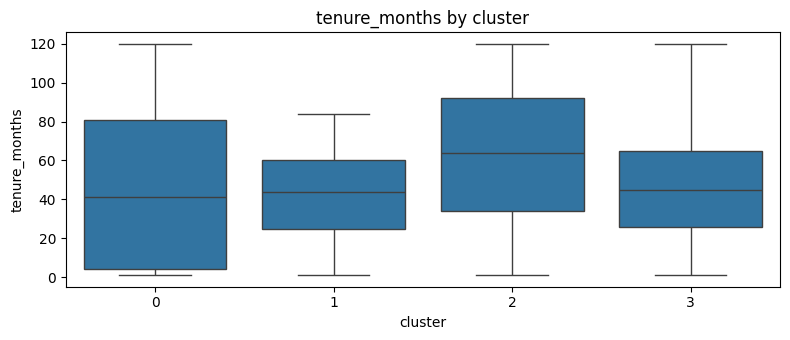

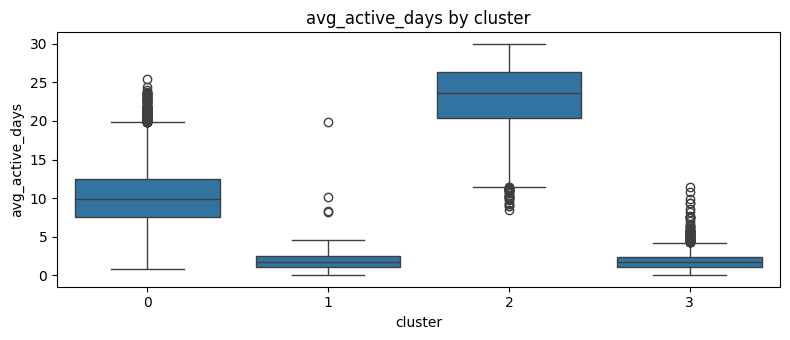

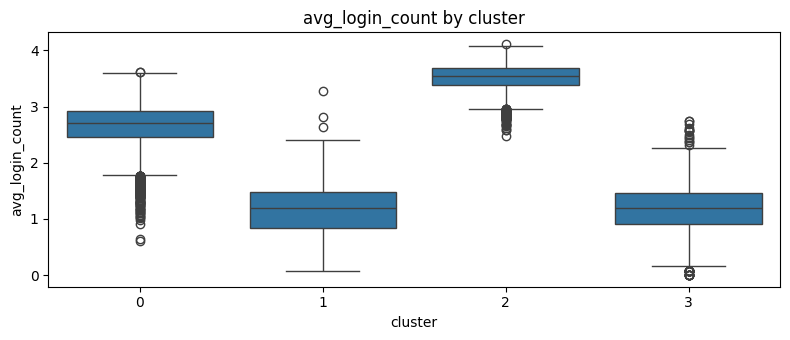

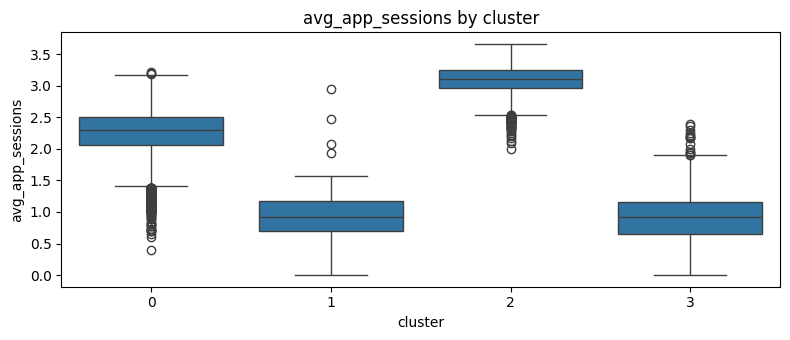

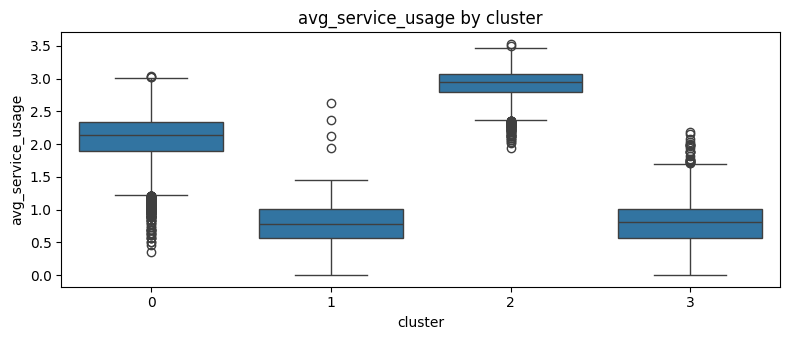

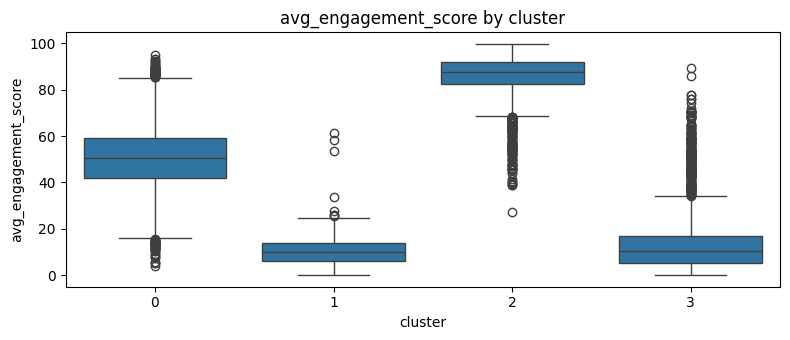

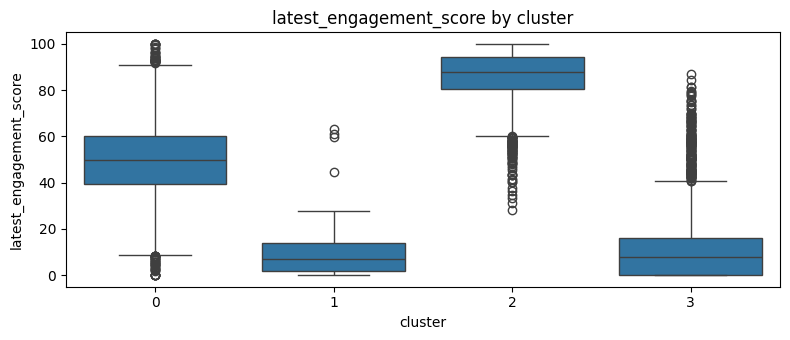

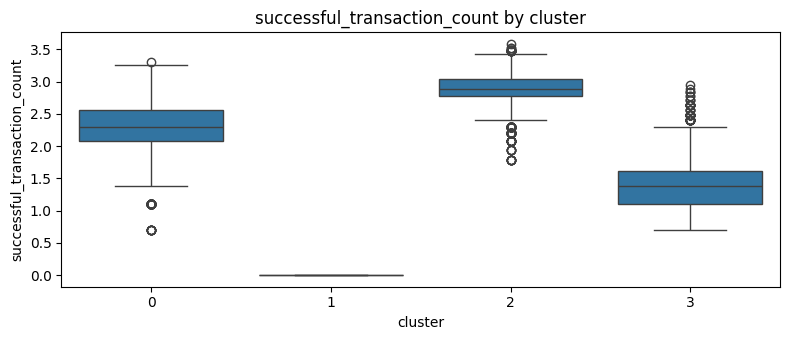

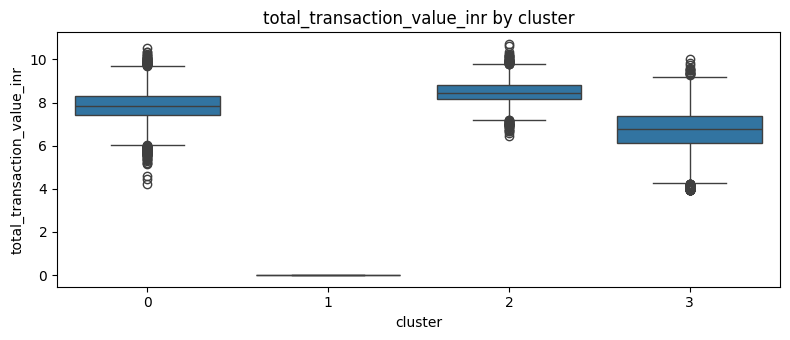

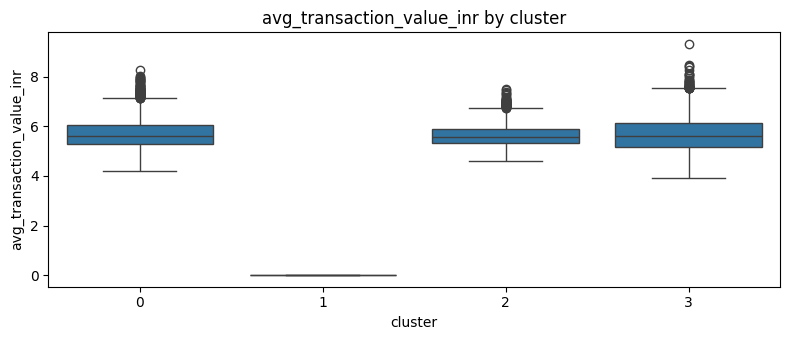

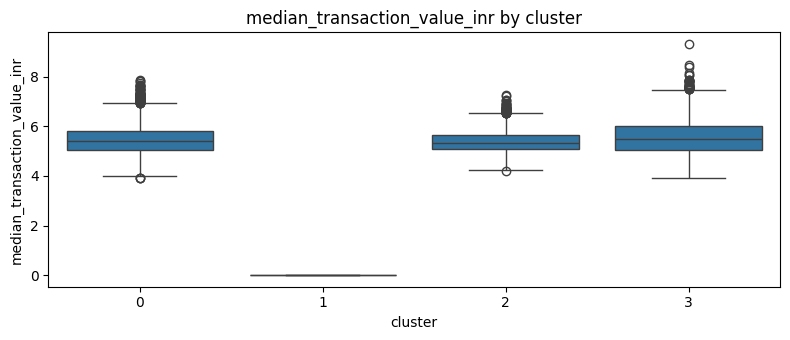

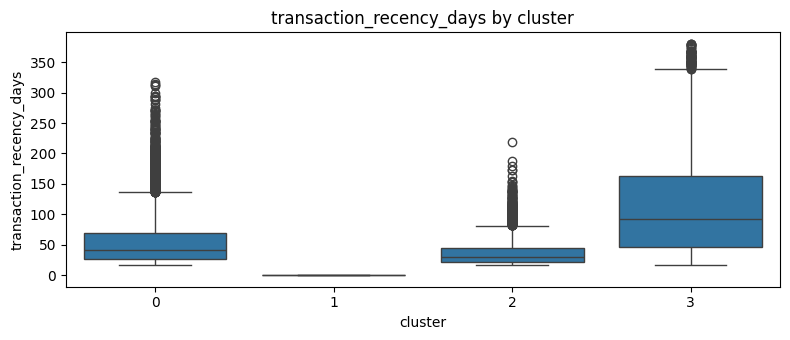

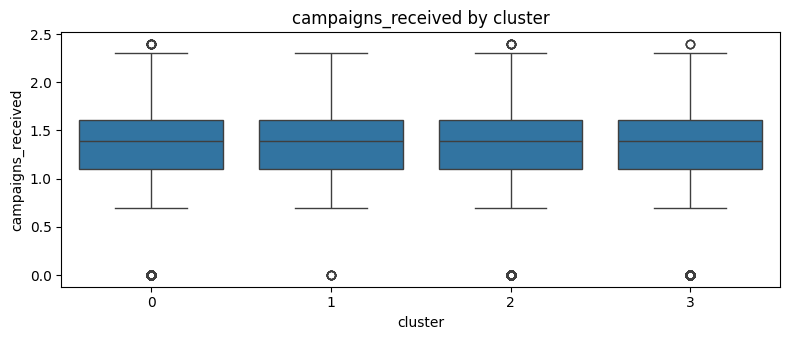

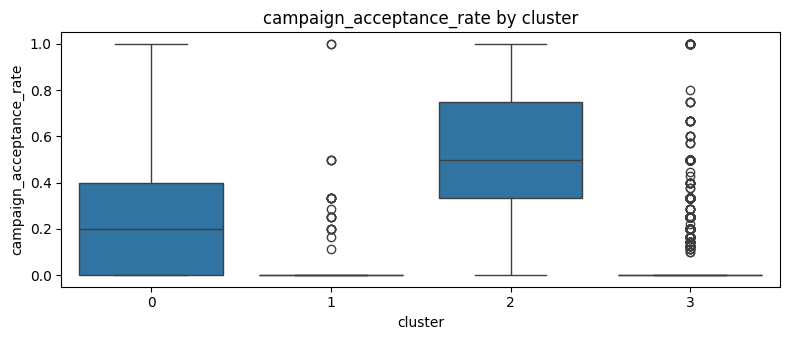

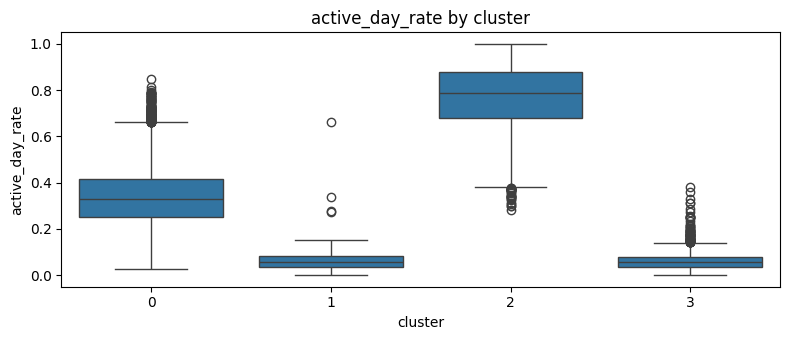

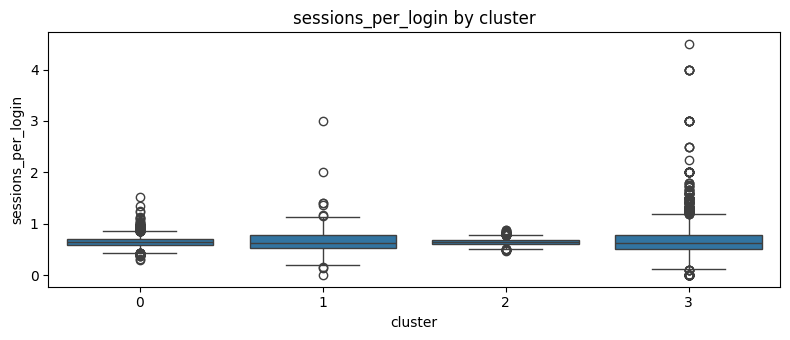

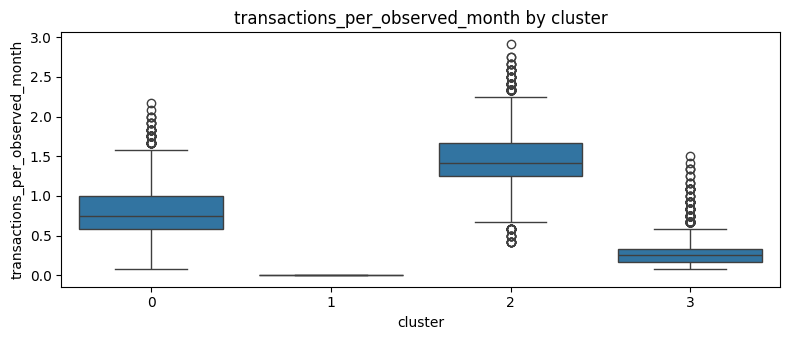

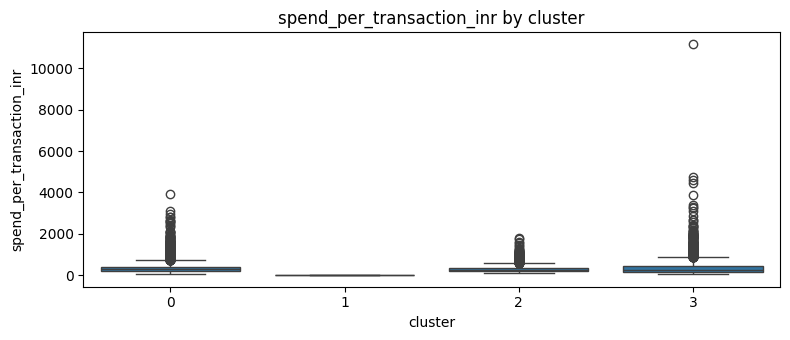

In [7]:
# Plot a small-multiple boxplot for each feature to see whether clusters differ.
for col in X.columns:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(data=profile_data, x='cluster', y=col)
    plt.title(f'{col} by cluster')
    plt.tight_layout()
    plt.show()


## 7. Optional: relate clusters to billing status without using it as an input

In [8]:
# Billing is a separate operational dimension, not a clustering feature.
billing_matches = list(MYDRIVE.rglob('customer_billing_reference.csv'))

if billing_matches:
    billing = pd.read_csv(billing_matches[0])
    print("Billing reference:", billing_matches[0])
    display(billing.head())

    if 'customer_id' in billing.columns and 'customer_id' in assignments.columns:
        joined = assignments.merge(billing, on='customer_id', how='left')
        candidate_status_cols = [
            c for c in joined.columns
            if any(term in c.lower() for term in ['billing_status', 'overdue_status', 'days_overdue'])
        ]
        print("Billing-related columns:", candidate_status_cols)

        for col in candidate_status_cols:
            if joined[col].nunique(dropna=True) <= 15:
                print(f"Distribution of {col} within behavioural clusters")
                display(pd.crosstab(
                    joined['cluster'], joined[col], normalize='index'
                ).round(3))
else:
    print("Billing reference file not found. Skipping this optional analysis.")


Billing reference: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k/processed/customer_billing_reference.csv


,customer_id,bill_count,total_amount_due_inr,total_amount_paid_inr,overdue_bill_count,avg_days_overdue,max_days_overdue
0,CUST000001,0.0,NaN,NaN,0.0,NaN,NaN
1,CUST000002,0.0,NaN,NaN,0.0,NaN,NaN
2,CUST000003,0.0,NaN,NaN,0.0,NaN,NaN
3,CUST000004,0.0,NaN,NaN,0.0,NaN,NaN
4,CUST000005,0.0,NaN,NaN,0.0,NaN,NaN


Billing-related columns: ['avg_days_overdue', 'max_days_overdue']


## 8. Save evaluation report

In [9]:
report = {
    'n_customers': int(len(assignments)),
    'n_features': int(X.shape[1]),
    'n_clusters': int(model.n_clusters),
    'silhouette_score_sample': float(sil_score),
    'davies_bouldin_index': float(db_score),
    'calinski_harabasz_index': float(ch_score),
    'pca_first_two_explained_variance': float(pca.explained_variance_ratio_.sum()),
    'cluster_sizes': {str(k): int(v) for k, v in cluster_counts.items()}
}

with open(SEGMENT_DIR / 'evaluation_report.json', 'w') as f:
    json.dump(report, f, indent=2)

evaluation_metrics.to_csv(SEGMENT_DIR / 'evaluation_metrics.csv', index=False)
size_summary.to_csv(SEGMENT_DIR / 'cluster_size_summary.csv')

print("Saved evaluation outputs to:", SEGMENT_DIR)
print("Evaluation complete.")


Saved evaluation outputs to: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k/processed/segmentation_outputs
Evaluation complete.


## 9. Decision checklist before Notebook 06

Review and write down:
- Are any clusters extremely small?
- Does the silhouette score indicate clear separation or substantial overlap?
- Does the PCA plot show some separation? Remember PCA is only a 2D projection.
- Which features distinguish each cluster?
- Do the clusters have understandable behavioural meaning?
- Does the billing cross-tab reveal a separate operational dimension?

**Next:** Notebook 06 — SHAP Explainability. We will train a surrogate classifier to predict the K-Means cluster labels, then use SHAP to explain which features drive those predictions. SHAP will explain the surrogate model, not K-Means directly.